# Avance 5 — Modelo final: ensambles
**Equipo 20 · Proyecto ML–SEDP (Green Stops, corredor CDMX–Acapulco)**

**Objetivo.** Estimar `log_tdpa` (tránsito diario promedio anual) en sitios sin aforo a partir de variables territoriales, para caracterizar los CTN del corredor MEX-095D. Siguiendo al sponsor, el modelo **no decide dónde construir**: aporta una estimación con incertidumbre y explicación.

En esta etapa se construyen ensambles **homogéneos** (Random Forest, Extra Trees, Gradient Boosting) y **heterogéneos** (Voting y Stacking con los mejores modelos individuales del Avance 4), se optimizan los hiperparámetros de los más relevantes, se comparan con los individuales y se elige el modelo final.

**Cambios respecto al Avance 4** (se reevalúan todos los modelos con el mismo esquema para que la comparación sea válida):
1. **Validación espacial por regiones contiguas.** Con los bloques de 25 km dispersos y la purga de 40 km, cada pliegue entrenaba en promedio con ≈143 de 703 sitios (≈20%) y en dos pliegues no había sitios de alto flujo. Ahora se agrupan los sitios en 15 regiones contiguas y se conserva **la misma purga de 40 km**; cada pliegue entrena con ≈63% de los datos (sección 1).
2. **Variables de red vial** (`red_*`), solicitadas en la presentación del sponsor (diap. 6 "distancia de red", diap. 8 "grafos"): accesibilidad gravitacional por tiempo de viaje sobre la RNC 2025 y tiempos a las zonas metropolitanas. Se calculan con `src/s09_red_features.py` y se integran en `FE_TOP_Model_Table_v2.csv`.

**Métrica principal:** RMSE en escala log. **Secundarias:** MAE log, R², Spearman (capacidad de ordenar sitios), acierto por categoría de tránsito (bajo/medio/alto), WAPE, MAE en vehículos/día y tiempo de entrenamiento. El corredor MEX-095D (23 aforos) queda reservado y se usa **una sola vez**, al final, con el modelo ya elegido.

In [1]:
from pathlib import Path
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, ElasticNet, RidgeCV
from sklearn.svm import SVR
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from sklearn.model_selection import GroupKFold, ParameterGrid, ParameterSampler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, confusion_matrix
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

import tdpa_comun as tc
from tdpa_comun import TARGET, CAT_COLS, PreparadorSeguro, preparar_datos, detectar_log, invertir_log, construir_folds
from validacion_regiones import construir_folds_regiones, regiones_contiguas

%matplotlib inline
warnings.filterwarnings("ignore")
SEED, THREADS = 20, 2
threadpool_limits(limits=THREADS)
np.random.seed(SEED)
pd.set_option("display.max_columns", 30)

ROOT = tc.encontrar_raiz()
TABLA = ROOT / "03_PROCESSED" / "FE_TOP_Model_Table_v2.csv"
TABLA_CTN = ROOT / "03_PROCESSED" / "FE_CTN_Prediction_Table_v2.csv"
OUT = ROOT / "06_RESULTS" / "AVANCE5"
MODELS_DIR = ROOT / "05_MODELS"
OUT.mkdir(parents=True, exist_ok=True); MODELS_DIR.mkdir(parents=True, exist_ok=True)
print("Tabla de modelado:", TABLA.name)

Tabla de modelado: FE_TOP_Model_Table_v2.csv


## 1. Datos y validación espacial
Se usa la tabla `_v2` (incluye las variables de red). El corredor de prueba y los sitios a menos de 40 km de él se separan desde `preparar_datos`, igual que en avances anteriores.

In [2]:
tabla, train, test = preparar_datos(TABLA)
modo_log, _ = detectar_log(train)
red_cols = [c for c in train.columns if c.startswith("red_")]
print("Variables de red:", red_cols)

folds = construir_folds_regiones(train)          # nueva validación (regiones contiguas + purga 40 km)
folds_anteriores = construir_folds(train)         # validación del Avance 4, sólo para comparar tamaños
ALTO = 40_000
filas = []
for (f, itr, iva), (_, itr0, _) in zip(folds, folds_anteriores):
    filas.append({"pliegue": f, "train_Avance4": len(itr0), "train_ahora": len(itr), "validación": len(iva),
                  "alto_flujo_train_Avance4": int((train.loc[itr0, "tdpa"] > ALTO).sum()),
                  "alto_flujo_train_ahora": int((train.loc[itr, "tdpa"] > ALTO).sum())})
tamanos = pd.DataFrame(filas)
display(tamanos)
print(f"Entrenamiento promedio: {tamanos.train_Avance4.mean():.0f} -> {tamanos.train_ahora.mean():.0f} sitios de {len(train)}")

Tabla maestra (1075, 279) | train 703 | test externo 23 | purgados 349
Variables de red: ['red_flujo_paso', 'red_grav_t2', 'red_grav_t1', 'red_tiempo_zmvm_min', 'red_tiempo_zm500k_min']


,pliegue,train_Avance4,train_ahora,validación,alto_flujo_train_Avance4,alto_flujo_train_ahora
0,1,127,487,141,11,50
1,2,150,489,145,4,64
2,3,197,394,147,34,52
3,4,105,423,136,10,49
4,5,138,436,134,5,69


Entrenamiento promedio: 143 -> 446 sitios de 703


**Interpretación.** Con la validación anterior, la purga de 40 km eliminaba ≈80% del entrenamiento en cada pliegue y algunos pliegues se quedaban casi sin sitios de alto flujo, de modo que se evaluaba un modelo muy distinto (y peor) del que se entrena al final con los 703 sitios. Con regiones contiguas, ningún sitio de entrenamiento queda a menos de 40 km de uno de validación (más que los ~25 km donde desaparece la autocorrelación del TDPA según el EDA), pero cada pliegue conserva ≈63% de los datos y todos tienen sitios de alto flujo. La evaluación sigue siendo espacial y es más representativa del uso real.

## 2. Funciones de evaluación
Todas las decisiones aprendidas (filtro de variables, transformaciones, PCA de clima) viven dentro de `PreparadorSeguro`, que se ajusta en cada pliegue sólo con datos de entrenamiento.

In [3]:
CORTES = train["tdpa"].quantile([1/3, 2/3]).to_numpy()   # límites de categoría bajo/medio/alto (veh/día)
print("Categorías de tránsito (veh/día): bajo <", CORTES.round(0)[0], "≤ medio <", CORTES.round(0)[1], "≤ alto")

def metricas(y_log, p_log, tdpa_real):
    y, p, real = (np.asarray(v, dtype=float) for v in (y_log, p_log, tdpa_real))
    pred = invertir_log(p, modo_log)
    return {"rmse_log": np.sqrt(mean_squared_error(y, p)), "mae_log": mean_absolute_error(y, p),
            "r2_log": r2_score(y, p), "spearman": spearmanr(y, p)[0],
            "acierto_categoria": float(np.mean(np.digitize(real, CORTES) == np.digitize(pred, CORTES))),
            "wape_pct": 100 * np.abs(real - pred).sum() / real.sum(), "mae_veh_dia": mean_absolute_error(real, pred)}

def evaluar_cv(nombre, fabrica, datos=train):
    filas, oof = [], pd.Series(np.nan, index=datos.index)
    for f, itr, iva in folds:
        tr, va = datos.loc[itr], datos.loc[iva]
        modelo = fabrica()
        t0 = time.perf_counter(); modelo.fit(tr, tr[TARGET]); seg = time.perf_counter() - t0
        p = modelo.predict(va); oof[iva] = p
        rmse_tr = np.sqrt(mean_squared_error(tr[TARGET], modelo.predict(tr)))
        filas.append({"modelo": nombre, "pliegue": f, "tiempo_seg": seg, "rmse_train": rmse_tr,
                      **metricas(va[TARGET], p, va["tdpa"])})
    return pd.DataFrame(filas), oof

def pipe(estimador):
    return Pipeline([("prep", PreparadorSeguro(modo="Filtro + PCA")), ("modelo", estimador)])

def ajustar(nombre, construir, configuraciones):
    filas = []
    for i, params in enumerate(configuraciones, 1):
        res, _ = evaluar_cv(nombre, lambda p=params: construir(p))
        filas.append({"configuración": i, "hiperparámetros": params, "rmse_log": res.rmse_log.mean(),
                      "sd_rmse": res.rmse_log.std(), "spearman": res.spearman.mean(), "tiempo_seg": res.tiempo_seg.mean()})
    return pd.DataFrame(filas).sort_values("rmse_log").reset_index(drop=True)

class BaselineGrupo(BaseEstimator, RegressorMixin):
    # Media de log_tdpa por tipo de vía y condición de cuota (mismo baseline de los avances anteriores)
    def __init__(self, grupos=("road_tipo_vial", "fe_peaje")):
        self.grupos = grupos
    def fit(self, X, y):
        g = list(self.grupos)
        self.medias_ = pd.Series(np.asarray(y), index=X.index).groupby([X[c] for c in g]).mean()
        self.global_ = float(np.mean(y)); return self
    def predict(self, X):
        idx = pd.MultiIndex.from_frame(X[list(self.grupos)])
        return self.medias_.reindex(idx).fillna(self.global_).to_numpy()

class RegionKFold:
    # Pliegues internos del stacking: regiones contiguas (partición completa, requisito de cross_val_predict)
    def __init__(self, n_splits=5, n_regiones=10, seed=SEED):
        self.n_splits, self.n_regiones, self.seed = n_splits, n_regiones, seed
    def split(self, X, y=None, groups=None):
        yield from GroupKFold(n_splits=self.n_splits).split(X, y, regiones_contiguas(X, self.n_regiones, self.seed))
    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits

RESULTADOS, OOF, FABRICAS, TIPO = [], {}, {}, {}
def registrar(nombre, fabrica, tipo):
    res, oof = evaluar_cv(nombre, fabrica)
    RESULTADOS.append(res); OOF[nombre] = oof; FABRICAS[nombre] = fabrica; TIPO[nombre] = tipo
    print(f"{nombre:38s} RMSE log = {res.rmse_log.mean():.4f} ± {res.rmse_log.std():.4f} | "
          f"Spearman = {res.spearman.mean():.3f} | {res.tiempo_seg.mean():.2f} s/pliegue")

Categorías de tránsito (veh/día): bajo < 6641.0 ≤ medio < 18448.0 ≤ alto


## 3. Referencia y mejores modelos individuales (Avance 4), reevaluados
Los tres mejores individuales del Avance 4 fueron Ridge, Elastic Net y SVR. Se reevalúan con la nueva validación y la tabla `_v2`. A Ridge, el mejor individual, se le ajusta `alpha` con una rejilla completa (en el Avance 4 el muestreo aleatorio no había probado los valores vecinos del óptimo).

In [4]:
registrar("Baseline (tipo de vía × cuota)", lambda: BaselineGrupo(), "Referencia")

aj_ridge = ajustar("Ridge", lambda p: pipe(Ridge(**p)), [{"alpha": a} for a in [1, 3, 10, 20, 30, 50, 100, 200, 500]])
display(aj_ridge[["hiperparámetros", "rmse_log", "sd_rmse", "spearman"]].head(5))
ALPHA = aj_ridge.loc[0, "hiperparámetros"]["alpha"]

registrar(f"Ridge (alpha={ALPHA})", lambda: pipe(Ridge(alpha=ALPHA)), "Individual")
registrar("Elastic Net", lambda: pipe(ElasticNet(alpha=0.01, l1_ratio=0.9, max_iter=20000, random_state=SEED)), "Individual")
registrar("SVR", lambda: pipe(SVR(kernel="rbf", C=10, epsilon=0.15, gamma="scale")), "Individual")

Baseline (tipo de vía × cuota)         RMSE log = 1.0575 ± 0.0593 | Spearman = 0.315 | 0.00 s/pliegue

,hiperparámetros,rmse_log,sd_rmse,spearman
0,{'alpha': 20},0.686983,0.072447,0.778852
1,{'alpha': 30},0.687091,0.076471,0.779274
2,{'alpha': 10},0.690144,0.065911,0.777187
3,{'alpha': 50},0.690619,0.081623,0.777829
4,{'alpha': 3},0.701910,0.057962,0.771931


Ridge (alpha=20)                       RMSE log = 0.6870 ± 0.0724 | Spearman = 0.779 | 0.38 s/pliegue


Elastic Net                            RMSE log = 0.6859 ± 0.0581 | Spearman = 0.775 | 0.39 s/pliegue


SVR                                    RMSE log = 0.7568 ± 0.0807 | Spearman = 0.695 | 0.41 s/pliegue


## 4. Ensambles homogéneos
Combinan muchas versiones del **mismo** tipo de modelo:
- **Random Forest** (bagging): árboles entrenados con muestras bootstrap y subconjuntos de variables; se promedian para reducir varianza.
- **Extra Trees** (bagging aleatorizado): cortes aleatorios, todavía menos varianza.
- **Gradient Boosting** (boosting): árboles secuenciales que corrigen los errores de los anteriores; reduce sesgo.

Se optimizan los hiperparámetros de los dos más relevantes (Random Forest y Gradient Boosting) con rejillas completas y la misma validación espacial. Se reporta la configuración base contra la ajustada (para Gradient Boosting, la base es la configuración del Avance 3).

In [5]:
# Random Forest: rejilla completa (12 configuraciones)
rf = lambda p: pipe(RandomForestRegressor(n_estimators=300, n_jobs=THREADS, random_state=SEED, **p))
RF_BASE = {"max_depth": None, "min_samples_leaf": 1, "max_features": 1.0}
rejilla_rf = [RF_BASE] + list(ParameterGrid({"max_depth": [None, 12], "min_samples_leaf": [2, 5, 10], "max_features": [0.3, 0.6]}))
aj_rf = ajustar("Random Forest", rf, rejilla_rf)
display(aj_rf[["hiperparámetros", "rmse_log", "sd_rmse", "spearman", "tiempo_seg"]].head(5))
RF_MEJOR = aj_rf.loc[0, "hiperparámetros"]
base_rf = aj_rf.loc[aj_rf["hiperparámetros"].apply(lambda d: d == RF_BASE), "rmse_log"].iloc[0]
print(f"Random Forest: base {base_rf:.4f} -> ajustado {aj_rf.loc[0, 'rmse_log']:.4f} "
      f"({100 * (1 - aj_rf.loc[0, 'rmse_log'] / base_rf):.1f}% de mejora) con {RF_MEJOR}")

,hiperparámetros,rmse_log,sd_rmse,spearman,tiempo_seg
0,"{'max_depth': 12, 'max_features': 0.3, 'min_sa...",0.694416,0.066548,0.762145,0.596112
1,"{'max_depth': None, 'max_features': 0.3, 'min_...",0.694532,0.066641,0.761928,0.588773
2,"{'max_depth': None, 'max_features': 0.3, 'min_...",0.696234,0.063543,0.762804,0.627163
3,"{'max_depth': 12, 'max_features': 0.3, 'min_sa...",0.696591,0.064469,0.762039,0.618746
4,"{'max_depth': 12, 'max_features': 0.3, 'min_sa...",0.697725,0.076410,0.764529,0.585664


Random Forest: base 0.7130 -> ajustado 0.6944 (2.6% de mejora) con {'max_depth': 12, 'max_features': 0.3, 'min_samples_leaf': 5}


In [6]:
# Gradient Boosting: rejilla completa alrededor de la configuración del Avance 3 (base)
import sklearn
gb = lambda p: pipe(HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **p))
GB_BASE = {"learning_rate": 0.05, "max_iter": 150, "min_samples_leaf": 20, "l2_regularization": 0.0}
espacio_gb = {"learning_rate": [0.03, 0.05], "max_iter": [150, 300], "min_samples_leaf": [20, 40], "l2_regularization": [0.0, 3.0]}
if tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 4):   # max_features existe desde scikit-learn 1.4
    GB_BASE["max_features"] = 1.0
    espacio_gb["max_features"] = [1.0, 0.5]
rejilla_gb = list(ParameterGrid(espacio_gb))
aj_gb = ajustar("Gradient Boosting", gb, rejilla_gb)
display(aj_gb[["hiperparámetros", "rmse_log", "sd_rmse", "spearman", "tiempo_seg"]].head(5))
GB_MEJOR = aj_gb.loc[0, "hiperparámetros"]
base_gb = aj_gb.loc[aj_gb["hiperparámetros"].apply(lambda d: d == GB_BASE), "rmse_log"].iloc[0]
print(f"Gradient Boosting: base {base_gb:.4f} -> ajustado {aj_gb.loc[0, 'rmse_log']:.4f} "
      f"({100 * (1 - aj_gb.loc[0, 'rmse_log'] / base_gb):.1f}% de mejora) con {GB_MEJOR}")
pd.concat([aj_rf.assign(modelo="Random Forest"), aj_gb.assign(modelo="Gradient Boosting")]).to_csv(
    OUT / "ajuste_hiperparametros.csv", index=False, encoding="utf-8-sig")

,hiperparámetros,rmse_log,sd_rmse,spearman,tiempo_seg
0,"{'l2_regularization': 0.0, 'learning_rate': 0....",0.690232,0.051325,0.762436,0.569295
1,"{'l2_regularization': 0.0, 'learning_rate': 0....",0.690812,0.052167,0.765189,0.573353
2,"{'l2_regularization': 3.0, 'learning_rate': 0....",0.691027,0.054191,0.759342,0.567198
3,"{'l2_regularization': 3.0, 'learning_rate': 0....",0.691473,0.049377,0.759889,0.719190
4,"{'l2_regularization': 3.0, 'learning_rate': 0....",0.692301,0.053827,0.766291,0.557808


Gradient Boosting: base 0.6940 -> ajustado 0.6902 (0.5% de mejora) con {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_features': 1.0, 'max_iter': 150, 'min_samples_leaf': 20}


In [7]:
registrar("Random Forest (ajustado)", lambda: rf(RF_MEJOR), "Ensamble homogéneo")
registrar("Extra Trees", lambda: pipe(ExtraTreesRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.6,
                                                         n_jobs=THREADS, random_state=SEED)), "Ensamble homogéneo")
registrar("Gradient Boosting (ajustado)", lambda: gb(GB_MEJOR), "Ensamble homogéneo")

Random Forest (ajustado)               RMSE log = 0.6944 ± 0.0665 | Spearman = 0.762 | 0.61 s/pliegue


Extra Trees                            RMSE log = 0.6778 ± 0.0809 | Spearman = 0.767 | 0.64 s/pliegue


Gradient Boosting (ajustado)           RMSE log = 0.6902 ± 0.0513 | Spearman = 0.762 | 0.58 s/pliegue


**Nota metodológica.** Los hiperparámetros se eligen con los mismos pliegues con los que se reporta el error, así que el RMSE de los modelos ajustados puede ser ligeramente optimista. Una validación anidada multiplicaría el costo; como control se reportan la desviación entre pliegues y, al final, la prueba externa en el corredor, que no se usó para ninguna decisión.

## 5. Ensambles heterogéneos
Combinan modelos **distintos**, que cometen errores diferentes. Como pide la actividad, se usan los mejores individuales de la fase previa (Ridge, Elastic Net y SVR) y se agrega el Gradient Boosting ajustado para aportar un modelo no lineal de árboles:
- **Voting:** promedio simple de las predicciones.
- **Stacking:** un meta-modelo (`RidgeCV`) aprende cuánto pesa cada modelo a partir de predicciones fuera de pliegue. Los pliegues internos también son regiones contiguas (`RegionKFold`), para que el meta-modelo no aprenda de predicciones con fuga espacial.

In [8]:
def modelos_base():
    return [("ridge", pipe(Ridge(alpha=ALPHA))),
            ("enet", pipe(ElasticNet(alpha=0.01, l1_ratio=0.9, max_iter=20000, random_state=SEED))),
            ("svr", pipe(SVR(kernel="rbf", C=10, epsilon=0.15, gamma="scale"))),
            ("gboost", gb(GB_MEJOR))]

registrar("Voting (Ridge+EN+SVR+GBoost)", lambda: VotingRegressor(modelos_base()), "Ensamble heterogéneo")
registrar("Stacking (Ridge+EN+SVR+GBoost)", lambda: StackingRegressor(
    modelos_base(), final_estimator=RidgeCV(alphas=np.logspace(-3, 2, 20)), cv=RegionKFold()), "Ensamble heterogéneo")

st = StackingRegressor(modelos_base(), final_estimator=RidgeCV(alphas=np.logspace(-3, 2, 20)), cv=RegionKFold()).fit(train, train[TARGET])
print("Pesos del meta-modelo del stacking:", dict(zip([n for n, _ in modelos_base()], st.final_estimator_.coef_.round(3))))

Voting (Ridge+EN+SVR+GBoost)           RMSE log = 0.6744 ± 0.0678 | Spearman = 0.782 | 1.74 s/pliegue


Stacking (Ridge+EN+SVR+GBoost)         RMSE log = 0.6743 ± 0.0468 | Spearman = 0.777 | 11.14 s/pliegue


Pesos del meta-modelo del stacking: {'ridge': np.float64(0.268), 'enet': np.float64(0.419), 'svr': np.float64(-0.05), 'gboost': np.float64(0.368)}


## 6. Tabla comparativa
Ordenada por la métrica principal (RMSE log, promedio de los 5 pliegues). `sd_rmse` mide la estabilidad entre regiones y `rmse_train` permite ver el sobreajuste. El tiempo es el de entrenamiento por pliegue.

In [9]:
res = pd.concat(RESULTADOS)
comparativa = (res.groupby("modelo").agg(
    rmse_log=("rmse_log", "mean"), sd_rmse=("rmse_log", "std"), mae_log=("mae_log", "mean"), r2_log=("r2_log", "mean"),
    spearman=("spearman", "mean"), acierto_categoria=("acierto_categoria", "mean"), wape_pct=("wape_pct", "mean"),
    mae_veh_dia=("mae_veh_dia", "mean"), rmse_train=("rmse_train", "mean"), tiempo_seg=("tiempo_seg", "mean"))
    .sort_values("rmse_log"))
comparativa.insert(0, "tipo", comparativa.index.map(TIPO))
base = comparativa.loc[comparativa.tipo == "Referencia", "rmse_log"].iloc[0]
comparativa["mejora_vs_baseline_pct"] = 100 * (1 - comparativa.rmse_log / base)
comparativa.to_csv(OUT / "tabla_comparativa.csv", encoding="utf-8-sig")
display(comparativa.style.format({"rmse_log": "{:.4f}", "sd_rmse": "{:.4f}", "mae_log": "{:.4f}", "r2_log": "{:.3f}",
    "spearman": "{:.3f}", "acierto_categoria": "{:.1%}", "wape_pct": "{:.1f}", "mae_veh_dia": "{:,.0f}",
    "rmse_train": "{:.4f}", "tiempo_seg": "{:.2f}", "mejora_vs_baseline_pct": "{:.1f}"}))

,tipo,rmse_log,sd_rmse,mae_log,r2_log,spearman,acierto_categoria,wape_pct,mae_veh_dia,rmse_train,tiempo_seg,mejora_vs_baseline_pct
modelo,,,,,,,,,,,,
Stacking (Ridge+EN+SVR+GBoost),Ensamble heterogéneo,0.6743,0.0468,0.5115,0.573,0.777,69.5%,47.7,"9,338",0.4656,11.14,36.2
Voting (Ridge+EN+SVR+GBoost),Ensamble heterogéneo,0.6744,0.0678,0.5079,0.574,0.782,70.7%,47.6,"9,358",0.4770,1.74,36.2
Extra Trees,Ensamble homogéneo,0.6778,0.0809,0.5197,0.571,0.767,68.0%,48.4,"9,586",0.3125,0.64,35.9
Elastic Net,Individual,0.6859,0.0581,0.5183,0.559,0.775,69.3%,49.5,"9,644",0.6147,0.39,35.1
Ridge (alpha=20),Individual,0.6870,0.0724,0.5184,0.558,0.779,69.7%,49.4,"9,619",0.5979,0.38,35.0
Gradient Boosting (ajustado),Ensamble homogéneo,0.6902,0.0513,0.5302,0.551,0.762,68.4%,48.7,"9,547",0.3352,0.58,34.7
Random Forest (ajustado),Ensamble homogéneo,0.6944,0.0665,0.5328,0.551,0.762,65.4%,48.9,"9,614",0.4493,0.61,34.3
SVR,Individual,0.7568,0.0807,0.5779,0.465,0.695,63.8%,53.3,"10,378",0.4463,0.41,28.4
Baseline (tipo de vía × cuota),Referencia,1.0575,0.0593,0.8576,-0.053,0.315,34.4%,72.0,"13,822",1.0114,0.00,0.0


## 7. Elección del modelo final
**Criterio, alineado con el negocio.** El modelo se usará para estimar y **ordenar** el tránsito de los CTN, donde no hay aforos, y para transferir el método a otros corredores. Por eso, además del RMSE, pesan: la **estabilidad entre regiones** (sd), la capacidad de **ordenar** sitios (Spearman) y de asignar la **categoría** correcta, el **sobreajuste** (brecha entre `rmse_train` y `rmse_log`) y el costo. Si dos modelos quedan a menos de una desviación estándar en RMSE, se prefiere el más estable y sencillo.

In [10]:
candidatos = comparativa[comparativa.tipo != "Referencia"]
# Regla: modelos a menos de 0.005 del mejor RMSE se consideran empatados (diferencia muy inferior a la sd entre pliegues);
# entre ellos gana el que mejor ORDENA los sitios (Spearman), porque el uso del modelo es comparar y caracterizar CTN.
empatados = candidatos[candidatos.rmse_log <= candidatos.rmse_log.min() + 0.005]
MODELO_FINAL = empatados.spearman.idxmax()
f = candidatos.loc[MODELO_FINAL]
otros = [m for m in empatados.index if m != MODELO_FINAL]
display(Markdown(
    f"**Modelo final: {MODELO_FINAL}** ({f.tipo.lower()}). RMSE log = {f.rmse_log:.4f} ± {f.sd_rmse:.4f}, "
    f"{f.mejora_vs_baseline_pct:.1f}% mejor que el baseline; Spearman = {f.spearman:.3f}; acierto de categoría = "
    f"{f.acierto_categoria:.1%}; {f.tiempo_seg:.2f} s por pliegue. Empatados en RMSE (±0.005): "
    + (", ".join(f"**{m}** (RMSE {candidatos.loc[m, 'rmse_log']:.4f}, sd {candidatos.loc[m, 'sd_rmse']:.4f}, "
                 f"Spearman {candidatos.loc[m, 'spearman']:.3f})" for m in otros) or "ninguno") + "."))

**Modelo final: Voting (Ridge+EN+SVR+GBoost)** (ensamble heterogéneo). RMSE log = 0.6744 ± 0.0678, 36.2% mejor que el baseline; Spearman = 0.782; acierto de categoría = 70.7%; 1.74 s por pliegue. Empatados en RMSE (±0.005): **Stacking (Ridge+EN+SVR+GBoost)** (RMSE 0.6743, sd 0.0468, Spearman 0.777), **Extra Trees** (RMSE 0.6778, sd 0.0809, Spearman 0.767).

**Justificación.** El **Voting** (promedio de Ridge, Elastic Net, SVR y Gradient Boosting) y el **Stacking** con los mismos modelos quedaron empatados en la métrica principal: RMSE log de 0.6744 y 0.6743, una diferencia de 0.0001, frente a una variación entre pliegues de 0.05–0.07. Ambos superan al mejor individual (Elastic Net, 0.686) y mejoran 36% sobre el baseline. Extra Trees también queda dentro del margen de empate (0.678), pero ordena peor (Spearman 0.767) y es el menos estable (sd 0.081). Se elige el **Voting** porque:
1. **Ordena mejor los sitios** (Spearman 0.782, el más alto de la tabla) y **acierta más la categoría** de tránsito (70.7%, también el más alto), que es lo que importa para comparar y caracterizar CTN.
2. Es **más simple y transparente**: un promedio simple, sin meta-modelo que ajustar, más fácil de explicar al sponsor.
3. Es **≈6 veces más rápido** de entrenar (1.7 s contra 11.1 s por pliegue).

La contrapartida es que el Stacking es **más estable entre regiones** (sd 0.047 contra 0.068). Ambos combinan lo mismo y los pesos que aprende el Stacking lo confirman: Elastic Net (0.42), Gradient Boosting (0.37) y Ridge (0.27), con SVR prácticamente en cero. Es decir, la ganancia viene de mezclar modelos lineales regularizados, que extrapolan bien la tendencia general (más accesibilidad, más tránsito), con árboles, que capturan umbrales (cuota, tipo de circulación). Los ensambles de árboles por sí solos sobreajustan con ≈450 sitios por pliegue (Gradient Boosting: `rmse_train` 0.34 contra 0.69 en validación); la combinación reduce esa brecha. La elección se contrasta con la prueba externa (sección 9), que no se usó en ninguna decisión.

## 8. Análisis del modelo final
Los gráficos usan las predicciones **fuera de pliegue** (cada sitio predicho por un modelo que no lo vio), así que reflejan el desempeño en regiones no vistas.

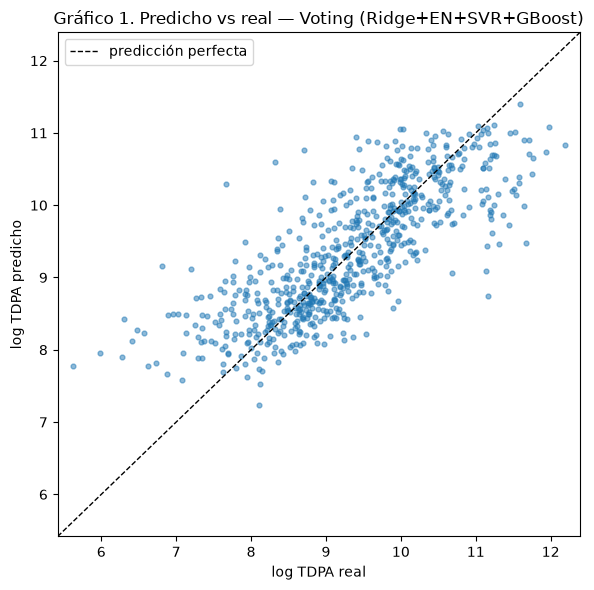

Pendiente de la recta real->predicho: 0.63 (1.0 = sin aplanamiento)


In [11]:
pred_oof = OOF[MODELO_FINAL]
y = train[TARGET]
resid = y - pred_oof
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y, pred_oof, s=12, alpha=0.5)
lim = [min(y.min(), pred_oof.min()) - 0.2, max(y.max(), pred_oof.max()) + 0.2]
ax.plot(lim, lim, "k--", lw=1, label="predicción perfecta")
ax.set(xlim=lim, ylim=lim, xlabel="log TDPA real", ylabel="log TDPA predicho", title=f"Gráfico 1. Predicho vs real — {MODELO_FINAL}")
ax.legend(); plt.tight_layout(); plt.savefig(OUT / "g1_predicho_vs_real.png", dpi=120); plt.show()
print(f"Pendiente de la recta real->predicho: {np.polyfit(y, pred_oof, 1)[0]:.2f} (1.0 = sin aplanamiento)")

**Interpretación del gráfico 1.** Los puntos siguen la diagonal, pero la nube es más plana que la línea de 45° (la pendiente impresa es menor que 1): el modelo **aplana los extremos**, sobreestima los sitios de poco tránsito y subestima los de mucho tránsito. Es el comportamiento típico cuando las variables no alcanzan a distinguir del todo una autopista muy cargada de un camino local. Para el uso del modelo (ordenar y caracterizar CTN) importa más que el orden se conserve, lo que se confirma con el Spearman.

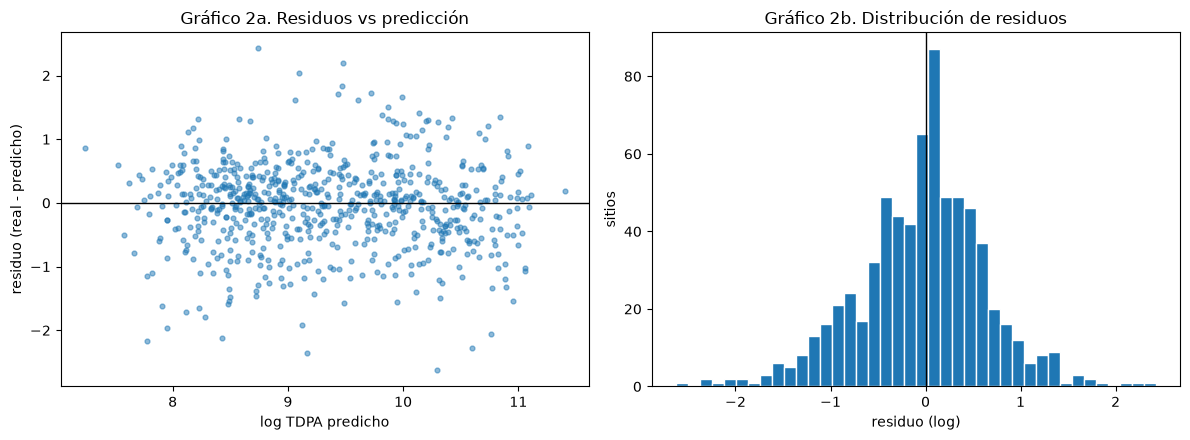

Media del residuo = -0.042 | mediana = 0.018 | |residuo| > 1 (error mayor a ×2.7): 13.7% de los sitios


In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].scatter(pred_oof, resid, s=12, alpha=0.5); axs[0].axhline(0, color="k", lw=1)
axs[0].set(xlabel="log TDPA predicho", ylabel="residuo (real - predicho)", title="Gráfico 2a. Residuos vs predicción")
axs[1].hist(resid, bins=40, edgecolor="white"); axs[1].axvline(0, color="k", lw=1)
axs[1].set(xlabel="residuo (log)", ylabel="sitios", title="Gráfico 2b. Distribución de residuos")
plt.tight_layout(); plt.savefig(OUT / "g2_residuos.png", dpi=120); plt.show()
print(f"Media del residuo = {resid.mean():.3f} | mediana = {resid.median():.3f} | "
      f"|residuo| > 1 (error mayor a ×2.7): {(resid.abs() > 1).mean():.1%} de los sitios")

**Interpretación del gráfico 2.** Los residuos están centrados en cero (mediana ≈0, sin sesgo global) y la mayoría cae dentro de ±1 en escala log. La forma en abanico del panel izquierdo muestra que los errores más grandes se concentran en los extremos de la predicción, y el histograma tiene colas: ≈14% de los sitios tienen errores mayores a un factor de 2.7. Al revisarlos en avances anteriores, muchos son aforos cuyo tramo de la RNC no coincide con lo que reporta SICT (por ejemplo, autopistas de cuota registradas como vialidades libres) o sitios en el entorno urbano de la CDMX.

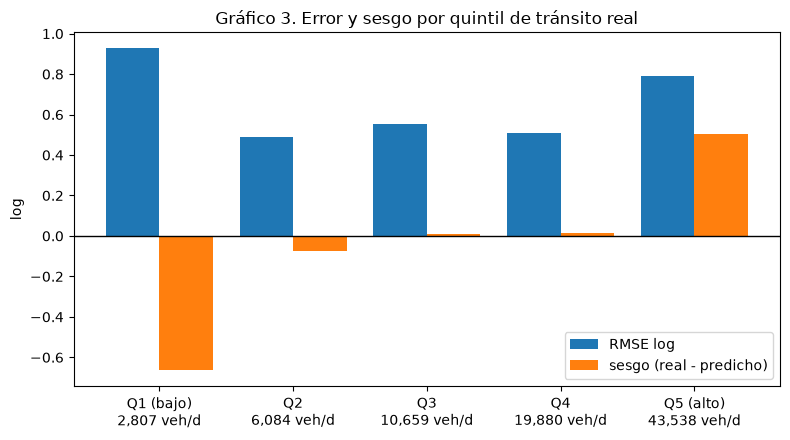

,rmse_log,sesgo,tdpa_mediana
tdpa,,,
Q1 (bajo),0.927,-0.662,2807.0
Q2,0.488,-0.077,6084.0
Q3,0.552,0.011,10659.0
Q4,0.510,0.014,19879.5
Q5 (alto),0.790,0.503,43538.0


In [13]:
quintil = pd.qcut(train["tdpa"], 5, labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])
por_q = pd.DataFrame({"rmse_log": resid.groupby(quintil).apply(lambda r: np.sqrt((r ** 2).mean())),
                      "sesgo": resid.groupby(quintil).mean(), "tdpa_mediana": train["tdpa"].groupby(quintil).median()})
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(5)
ax.bar(x - 0.2, por_q.rmse_log, 0.4, label="RMSE log"); ax.bar(x + 0.2, por_q.sesgo, 0.4, label="sesgo (real - predicho)")
ax.axhline(0, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels([f"{q}\n{m:,.0f} veh/d" for q, m in zip(por_q.index, por_q.tdpa_mediana)])
ax.set(title="Gráfico 3. Error y sesgo por quintil de tránsito real", ylabel="log"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "g3_error_por_quintil.png", dpi=120); plt.show()
display(por_q.round(3))

**Interpretación del gráfico 3.** El error es menor en los quintiles intermedios y crece en los extremos. El sesgo es negativo en el quintil bajo (el modelo **sobreestima** los caminos de poco tránsito) y positivo en el alto (**subestima** las autopistas más cargadas). Implicación práctica: para los CTN de la MEX-095D, que es una autopista de cuota de alto flujo, las estimaciones tenderán a quedarse cortas en términos absolutos; por eso se recomienda usarlas para **comparar** nodos entre sí y, donde existan aforos cercanos, apoyarse en ellos (sección 9).

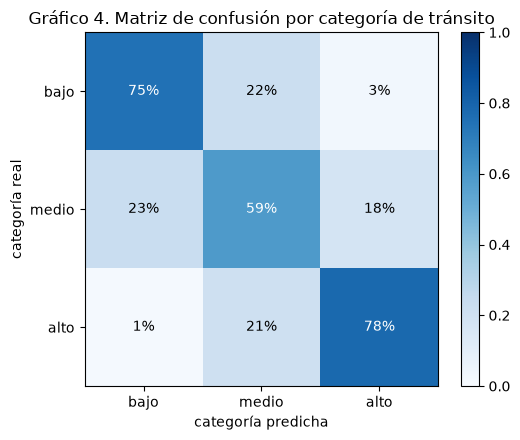

Acierto global: 70.6% | errores graves (bajo <-> alto): 1.4%


In [14]:
etiquetas = ["bajo", "medio", "alto"]
real_c = np.digitize(train["tdpa"], CORTES)
pred_c = np.digitize(invertir_log(pred_oof.to_numpy(), modo_log), CORTES)
cm = confusion_matrix(real_c, pred_c, normalize="true")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
ax.set(xticks=range(3), yticks=range(3), xticklabels=etiquetas, yticklabels=etiquetas,
       xlabel="categoría predicha", ylabel="categoría real", title="Gráfico 4. Matriz de confusión por categoría de tránsito")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(OUT / "g4_matriz_confusion.png", dpi=120); plt.show()
print(f"Acierto global: {(real_c == pred_c).mean():.1%} | errores graves (bajo <-> alto): {(np.abs(real_c - pred_c) == 2).mean():.1%}")

**Interpretación del gráfico 4.** Al convertir la predicción en categorías (terciles del TDPA de entrenamiento), el modelo acierta la mayoría de los sitios de tránsito bajo y alto; la categoría media es la más difícil, porque sus errores caen en las vecinas. Los **errores graves** (confundir un sitio bajo con uno alto o al revés) son muy poco frecuentes. Para la caracterización de Green Stops esto es lo relevante: el modelo distingue con confiabilidad los nodos de paso de alto flujo de los nodos rurales de poco tránsito.

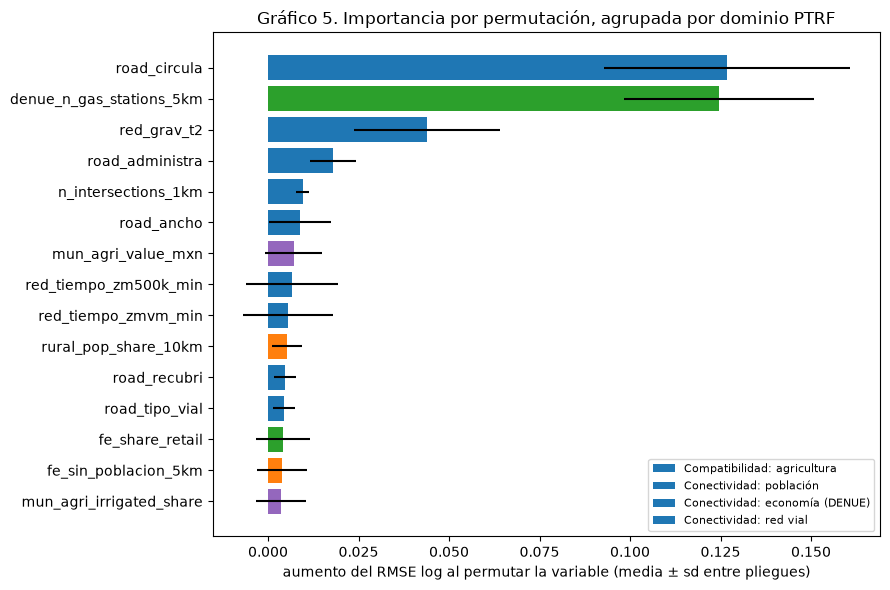

,mean,std,pliegues_en_top10,dominio
variable,,,,
road_circula,0.1268,0.0339,5,Conectividad: red vial
denue_n_gas_stations_5km,0.1246,0.0263,5,Conectividad: economía (DENUE)
red_grav_t2,0.0439,0.0201,5,Conectividad: red vial
road_administra,0.0179,0.0065,5,Conectividad: red vial
n_intersections_1km,0.0096,0.0017,5,Conectividad: red vial
road_ancho,0.0088,0.0085,2,Conectividad: red vial
mun_agri_value_mxn,0.0071,0.0078,3,Compatibilidad: agricultura
red_tiempo_zm500k_min,0.0066,0.0127,1,Conectividad: red vial
red_tiempo_zmvm_min,0.0056,0.0125,1,Conectividad: red vial


dominio
Conectividad: red vial            0.2315
Conectividad: economía (DENUE)    0.1326
Conectividad: población           0.0105
Compatibilidad: agricultura       0.0079
Soporte: clima/solar              0.0007
Name: importancia_total, dtype: float64

In [15]:
DOMINIOS = [("Conectividad: red vial", ("road_", "red_", "n_intersections", "fe_peaje", "fe_carriles", "fe_densidad_intersecciones", "fe_rnc")),
            ("Conectividad: población", ("pop_", "n_localities", "rural_pop", "fe_pop", "fe_densidad_pob", "fe_densidad_anillo",
                                          "fe_sin_poblacion", "fe_concentracion", "dist_nearest", "pop_nearest", "schooling", "pct_dwellings")),
            ("Conectividad: economía (DENUE)", ("denue_", "fe_share", "fe_servicios", "fe_hay_gasolinera", "fe_est_", "fe_densidad_est", "fe_sin_establecimientos")),
            ("Soporte: clima/solar", ("allsky", "prectotcorr", "t2m", "ws10m")),
            ("Compatibilidad: agricultura", ("mun_agri", "fe_agri"))]
def dominio(c):
    for nombre, prefijos in DOMINIOS:
        if c.startswith(prefijos):
            return nombre
    return "Otras"

imps = []
for f, itr, iva in folds:
    tr, va = train.loc[itr], train.loc[iva]
    prep = PreparadorSeguro(modo="Filtro + PCA").fit(tr, tr[TARGET])
    columnas = list(dict.fromkeys(prep.num_seleccionadas_ + prep.cat_seleccionadas_ + prep.pca_cols_))
    modelo = FABRICAS[MODELO_FINAL]().fit(tr, tr[TARGET])
    base_rmse = np.sqrt(mean_squared_error(va[TARGET], modelo.predict(va)))
    rng = np.random.default_rng(SEED)
    for c in columnas:
        subidas = []
        for _ in range(3):
            vp = va.copy(); vp[c] = rng.permutation(vp[c].to_numpy())
            subidas.append(np.sqrt(mean_squared_error(va[TARGET], modelo.predict(vp))) - base_rmse)
        imps.append({"pliegue": f, "variable": c, "aumento_rmse": float(np.mean(subidas))})
imp = pd.DataFrame(imps).pivot_table(index="pliegue", columns="variable", values="aumento_rmse").fillna(0.0)  # no seleccionada = 0
resumen_imp = pd.DataFrame({"mean": imp.mean(), "std": imp.std(),
                            "pliegues_en_top10": (imp.rank(axis=1, ascending=False) <= 10).sum()}).sort_values("mean", ascending=False)
resumen_imp["dominio"] = resumen_imp.index.map(dominio)
top = resumen_imp.head(15).iloc[::-1]
colores = dict(zip([d for d, _ in DOMINIOS] + ["Otras"], plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["mean"], xerr=top["std"], color=[colores[d] for d in top.dominio])
for d in top.dominio.unique():
    ax.barh([], [], color=colores[d], label=d)
ax.set(xlabel="aumento del RMSE log al permutar la variable (media ± sd entre pliegues)",
       title="Gráfico 5. Importancia por permutación, agrupada por dominio PTRF"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "g5_importancia.png", dpi=120); plt.show()
display(resumen_imp.head(10).round(4))
display(resumen_imp.groupby("dominio")["mean"].sum().clip(lower=0).sort_values(ascending=False).rename("importancia_total").round(4))
resumen_imp.to_csv(OUT / "importancia_permutacion.csv", encoding="utf-8-sig")

**Interpretación del gráfico 5.** La importancia se calcula en cada pliegue sobre datos de validación (permutar una variable y medir cuánto empeora el RMSE). Las cinco variables principales aparecen en el top 10 de **los 5 pliegues**, así que la explicación es **estable**, uno de los criterios de "éxito de ML" de la presentación del sponsor:
- `road_circula` (tipo de circulación de la RNC): identifica las vías de cuerpos separados, típicas de autopistas.
- `denue_n_gas_stations_5km` (gasolineras a 5 km): predice bien porque las gasolineras existen *gracias* al tránsito; describe asociación, no causa.
- `red_grav_t2` (accesibilidad por tiempo de viaje a las zonas metropolitanas): la variable de red solicitada por el sponsor, tercera en importancia.
- `road_administra` y `n_intersections_1km`: quién administra la vía (federal/estatal) y la densidad de entronques.

Por dominio PTRF, ≈60% de la importancia total corresponde a **Conectividad: red vial** y ≈35% a **Conectividad: economía (DENUE)**. El **Soporte** solar y la **Compatibilidad** agrícola casi no contribuyen, coherente con el EDA (la radiación varía poco a lo largo del corredor). Para el tránsito, lo decisivo es qué tan conectado está el sitio, no sus condiciones energéticas o agrícolas; esas dimensiones serán relevantes en la caracterización del Green Stop, no en la estimación de demanda.

## 9. Prueba externa: corredor MEX-095D (datos no vistos)
El modelo final se reentrena con los 703 sitios de entrenamiento y se evalúa **una sola vez** sobre los 23 aforos de la MEX-095D, que no se usaron en ninguna decisión de esta etapa. Como referencia adicional se estima cada aforo interpolando por kilómetro entre los aforos vecinos de la misma autopista (dejando uno fuera).

,rmse_log,mae_log,r2_log,spearman,acierto_categoria,wape_pct,mae_veh_dia
Modelo final (ML),0.653,0.514,0.308,0.627,70%,44.4,"15,988"
Interpolación entre aforos vecinos,0.280,0.172,0.873,0.921,100%,19.7,"7,099"


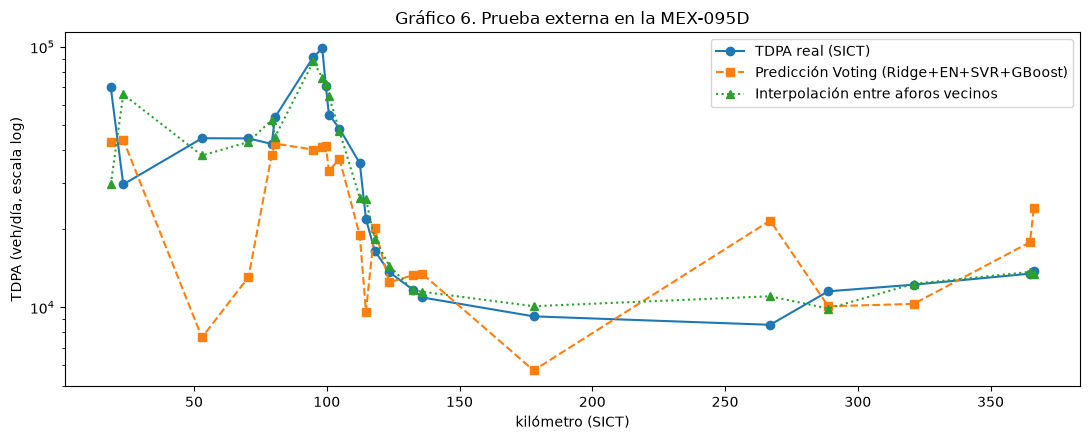

In [16]:
modelo_final = FABRICAS[MODELO_FINAL]().fit(train, train[TARGET])
joblib.dump(modelo_final, MODELS_DIR / "avance5_modelo_final.joblib")
T = test.sort_values("KM").copy()
T["pred"] = modelo_final.predict(T)
yT, km = T[TARGET].to_numpy(), T["KM"].to_numpy(float)
interp = np.array([np.interp(km[i], np.delete(km, i), np.delete(yT, i)) for i in range(len(T))])
ext = pd.DataFrame({"Modelo final (ML)": metricas(yT, T["pred"], T["tdpa"]),
                    "Interpolación entre aforos vecinos": metricas(yT, interp, T["tdpa"])}).T
display(ext.style.format({"rmse_log": "{:.3f}", "mae_log": "{:.3f}", "r2_log": "{:.3f}", "spearman": "{:.3f}",
                          "acierto_categoria": "{:.0%}", "wape_pct": "{:.1f}", "mae_veh_dia": "{:,.0f}"}))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(km, T["tdpa"], "o-", label="TDPA real (SICT)")
ax.plot(km, invertir_log(T["pred"].to_numpy(), modo_log), "s--", label=f"Predicción {MODELO_FINAL}")
ax.plot(km, invertir_log(interp, modo_log), "^:", label="Interpolación entre aforos vecinos")
ax.set_yscale("log"); ax.set(xlabel="kilómetro (SICT)", ylabel="TDPA (veh/día, escala log)",
                             title="Gráfico 6. Prueba externa en la MEX-095D")
ax.legend(); plt.tight_layout(); plt.savefig(OUT / "g6_prueba_externa.png", dpi=120); plt.show()
ext.to_csv(OUT / "prueba_externa.csv", encoding="utf-8-sig")

**Interpretación del gráfico 6.** En los 23 aforos del corredor, el modelo final obtiene RMSE log de 0.65, R² de 0.31, Spearman de 0.63 y acierta la categoría en 70% de los aforos: reproduce la forma general del perfil (más tránsito en la salida de la CDMX y alrededor de Cuernavaca, menos en el tramo de Guerrero), pero con el aplanamiento ya visto. Los errores más grandes están en el **tramo de montaña** entre la CDMX y Cuernavaca (Tres Marías y el km 70), donde casi no hay población ni comercios alrededor pero pasa todo el tránsito entre ambas ciudades: el modelo los confunde con caminos rurales. La interpolación entre aforos vecinos es mucho más precisa **en este corredor** (R² 0.87, Spearman 0.92), porque la MEX-095D tiene 23 aforos y el tránsito cambia de forma gradual a lo largo de la autopista. Recomendación de uso: **en corredores con aforos, la estimación de los CTN debe apoyarse en los aforos vecinos; el modelo de ML aporta en los tramos sin aforos cercanos (el hueco entre los km 178 y 267) y, sobre todo, para transferir el método a corredores sin aforos**, que es parte del propósito del proyecto.

## 10. Estimación para los CTN con incertidumbre
El entregable del sponsor es *CTN → predicción → confianza → explicación*. Para la confianza se entrenan dos modelos de Gradient Boosting por cuantiles (percentiles 10 y 90). Como los cuantiles por sí solos suelen quedarse cortos fuera de la región de entrenamiento, se **calibran con predicción conformal (CQR)**: con las predicciones fuera de pliegue se calcula cuánto hay que ensanchar el intervalo para que cubra el 80% de los sitios en validación espacial.

Cobertura del intervalo 10–90 sin calibrar: 71.6% (nominal 80%)
Ajuste conformal: ±0.175 en log (factor ×1.19) -> cobertura calibrada 80.1%


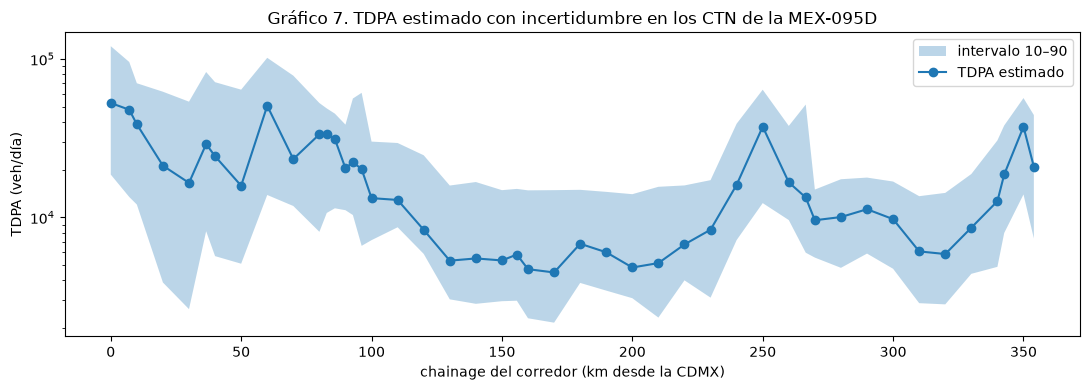

,ctn_id,chainage_km,tdpa_estimado,tdpa_p10,tdpa_p90,categoria
0,CTN_000,0.000,52694.0,18617.0,120412.0,alto
1,CTN_001,7.086,47800.0,13443.0,95663.0,alto
2,CTN_002,10.000,38680.0,12043.0,70231.0,alto
3,CTN_003,20.000,21190.0,3877.0,62087.0,alto
4,CTN_004,30.000,16507.0,2633.0,53738.0,medio
5,CTN_005,36.574,29011.0,8173.0,82678.0,alto
6,CTN_006,40.000,24303.0,5690.0,71313.0,alto
7,CTN_007,50.000,15835.0,5096.0,63976.0,medio
8,CTN_008,60.000,50607.0,13841.0,101631.0,alto
9,CTN_009,70.000,23326.0,11793.0,78439.0,alto


In [17]:
cuantil = lambda a: pipe(HistGradientBoostingRegressor(loss="quantile", quantile=a, early_stopping=False, random_state=SEED,
                                                       **{k: v for k, v in GB_MEJOR.items()}))
lo_oof, hi_oof = pd.Series(np.nan, index=train.index), pd.Series(np.nan, index=train.index)
for f, itr, iva in folds:
    tr, va = train.loc[itr], train.loc[iva]
    lo_oof[iva] = cuantil(0.10).fit(tr, tr[TARGET]).predict(va)
    hi_oof[iva] = cuantil(0.90).fit(tr, tr[TARGET]).predict(va)
cob_cruda = np.mean((y >= lo_oof) & (y <= hi_oof))
# Calibración conformal (CQR): cuánto hay que ensanchar el intervalo para cubrir el 80% en validación espacial
score = np.maximum(lo_oof - y, y - hi_oof)
Q = float(np.quantile(score, min(1.0, 0.80 * (1 + 1 / len(score)))))
cob_cal = np.mean((y >= lo_oof - Q) & (y <= hi_oof + Q))
print(f"Cobertura del intervalo 10–90 sin calibrar: {cob_cruda:.1%} (nominal 80%)")
print(f"Ajuste conformal: ±{Q:.3f} en log (factor ×{np.exp(Q):.2f}) -> cobertura calibrada {cob_cal:.1%}")

ctn = pd.read_csv(TABLA_CTN, low_memory=False)
lo_m, hi_m = cuantil(0.10).fit(train, train[TARGET]), cuantil(0.90).fit(train, train[TARGET])
p, p10, p90 = modelo_final.predict(ctn), lo_m.predict(ctn), hi_m.predict(ctn)
salida = pd.DataFrame({"ctn_id": ctn["ctn_id"], "chainage_km": ctn["chainage_km"],
                       "tdpa_estimado": invertir_log(p, modo_log).round(0),
                       "tdpa_p10": invertir_log(np.minimum(p10 - Q, p), modo_log).round(0),
                       "tdpa_p90": invertir_log(np.maximum(p90 + Q, p), modo_log).round(0)})
salida["categoria"] = pd.Categorical.from_codes(np.digitize(salida.tdpa_estimado, CORTES), etiquetas)
salida.to_csv(OUT / "predicciones_ctn.csv", index=False, encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(salida.chainage_km, salida.tdpa_p10, salida.tdpa_p90, alpha=0.3, label="intervalo 10–90")
ax.plot(salida.chainage_km, salida.tdpa_estimado, "o-", label="TDPA estimado")
ax.set_yscale("log"); ax.set(xlabel="chainage del corredor (km desde la CDMX)", ylabel="TDPA (veh/día)",
                             title="Gráfico 7. TDPA estimado con incertidumbre en los CTN de la MEX-095D")
ax.legend(); plt.tight_layout(); plt.savefig(OUT / "g7_ctn_incertidumbre.png", dpi=120); plt.show()
display(salida.head(10))

**Interpretación del gráfico 7.** Cada CTN tiene una estimación y un intervalo. Sin calibrar, el intervalo 10–90 cubría sólo ≈72% de los sitios en validación espacial (los cuantiles se quedan cortos en regiones no vistas); con la calibración conformal se ensancha por un factor de ≈1.19 y la cobertura llega a ≈80%, la nominal. Los intervalos son anchos, lo que es honesto con la incertidumbre de estimar tránsito sin aforo, y son una señal para el sponsor: los CTN con intervalos más amplios son donde un **aforo nuevo** reduciría más la incertidumbre (idea de *active learning* de la presentación). Por el sesgo del gráfico 3, en los tramos de alto flujo el valor real tiende a estar en la parte alta del intervalo.

## 11. Conclusiones
1. **Ensambles.** Se construyeron 5 ensambles: 3 homogéneos (Random Forest, Extra Trees, Gradient Boosting) y 2 heterogéneos (Voting y Stacking con los mejores individuales del Avance 4 más Gradient Boosting). La optimización con rejillas completas y validación espacial mejoró Random Forest 2.6% y Gradient Boosting 0.5% (la configuración del Avance 3 ya estaba cerca del óptimo), y llevó el `alpha` de Ridge de 10 a 20.
2. **Modelo final: Voting.** RMSE log de 0.674 en validación espacial, 36% mejor que el baseline, el mejor Spearman (0.78) y 71% de acierto en la categoría de tránsito, con sólo 1.4% de errores graves (confundir bajo con alto). Quedó empatado con el Stacking (diferencia de 0.0001 en RMSE); se eligió por ordenar mejor los sitios, ser más simple y más rápido. En el corredor de prueba, no usado en ninguna decisión, obtuvo R² de 0.31 y Spearman de 0.63.
3. **Validación.** Cambiar a regiones contiguas, manteniendo la purga de 40 km, corrigió un problema del diseño anterior (pliegues con ≈20% de los datos) y da una evaluación más representativa del modelo que se usará.
4. **Lo que aprendimos del territorio** (pregunta guía del sponsor): el tránsito depende sobre todo de la **conectividad**: el tipo de vía, la accesibilidad por tiempo de viaje a las zonas metropolitanas y la actividad económica asociada, más que de la población local; el soporte solar casi no diferencia sitios en este corredor; y existen inconsistencias entre fuentes oficiales (aforos de cuota que la RNC registra como libres) que limitan la precisión.
5. **Límites.** El modelo aplana los extremos: sobreestima caminos de poco tránsito y subestima autopistas muy cargadas, en especial tramos de paso sin población alrededor (la montaña entre la CDMX y Cuernavaca). Debe usarse para **comparar y caracterizar** CTN, no como cifra exacta de tránsito ni como decisión de construcción.
6. **Recomendaciones y trabajo futuro.** En corredores con aforos, combinar el modelo con interpolación entre aforos vecinos; corregir la asignación de aforos a la RNC usando el nombre de la carretera y el kilómetro; mejorar la variable de flujo de paso (más ciudades de origen y conectividad de la red); evaluar la GraphSAGE con grafos sobre la red vial; y priorizar un aforo en el tramo km 178–267, donde la incertidumbre es mayor.

## Declaración sobre el uso de herramientas de inteligencia artificial

Se utilizaron ChatGPT (OpenAI) y Claude (Anthropic) como apoyo para revisar los requisitos de la actividad, diagnosticar el diseño de la validación espacial, proponer y programar las variables de red vial, organizar el código del notebook, proponer espacios de búsqueda de hiperparámetros y redactar borradores de las interpretaciones. El equipo es responsable de revisar, ejecutar, interpretar y validar el código, los resultados y las conclusiones antes de la entrega.